# Two-sector primitive CNOT — Stage 2: hub circuit

Stage 2 of `plans/xz_noise_hub_cnot.md`, simulated with `cnot_primitive_xz.jl` (`SCHEDULE=hub`; local first pass from `jobs/cnot_primitive_xz_hub_local.jl`).

Circuit: the hub A (always the target) does `N` noisy CNOT rounds with fresh partners, one every `k + 1 = d + 1` rounds. Each partner gets `d` rounds, its CNOT round, and `d` rounds, then readout. A gets `d` rounds before its first CNOT and `d` after its last. Noise: single-qubit depolarizing `p`, measurement `q = p`, two-qubit depolarizing `p2 = 10p` at each CNOT; primitive rule mirrored per sector.

Metrics (plan Section 8):

- **headline per-gate rate** `eps_CNOT`: slope of the total failure probability (any block, either sector) over `N`, from `1 - P(N) = B (1 - eps_CNOT)^N` (Google style; `B` absorbs A's first and last `d` rounds);
- **own-fault decomposition**: logical-frame snapshots remove faults propagated from other blocks, giving per-gate hub X/Z and per-partner X/Z own rates;
- **suppression factor** `Lambda_CNOT` from regressing `ln eps_CNOT` on `(L+1)/2`;
- **threshold**: with `k = d` every gate adds a fixed spacetime volume, so the finite-size crossing of `eps_CNOT` is the Lake-style threshold, and the point where `Lambda_CNOT = 1` is a cross-check.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

PROJECT_DIR = next(
    (path for path in (Path.cwd(), Path.cwd().parent) if (path / "notebooks/analysis_utils.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks.")
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    P_MAX_BLOCK,
    display_finite_size_scaling_fit,
    display_fit_summary,
    fit_decay_rate,
    fit_finite_size_scaling,
    fit_lambda,
    hub_gate_rates,
    hub_rate_grids,
    lambda_ratios,
    load_ft_scan,
    load_hub_records,
    rates_as_scan,
)

GAP = "d"
HUB_DIR = PROJECT_DIR / "results/cnot_primitive_xz/hub" / f"k_{GAP}"
groups = load_hub_records(HUB_DIR)
L_VALUES = sorted({key[1] for key in groups})
P_VALUES = sorted({key[2] for key in groups})
N_VALUES = sorted({key[3] for key in groups})
print(f"{len(groups)} (L, p, N) points from {sum(g['files'] for g in groups.values())} files")
print("L:", L_VALUES)
print("p:", P_VALUES)
print("N:", N_VALUES)

220 (L, p, N) points from 220 files
L: [5, 7, 9, 11, 13]
p: [0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.011, 0.012, 0.013, 0.014]
N: [1, 2, 4, 8]


## 1. Raw failure probabilities

Total failure probability (any block, either sector) for each number of CNOTs.

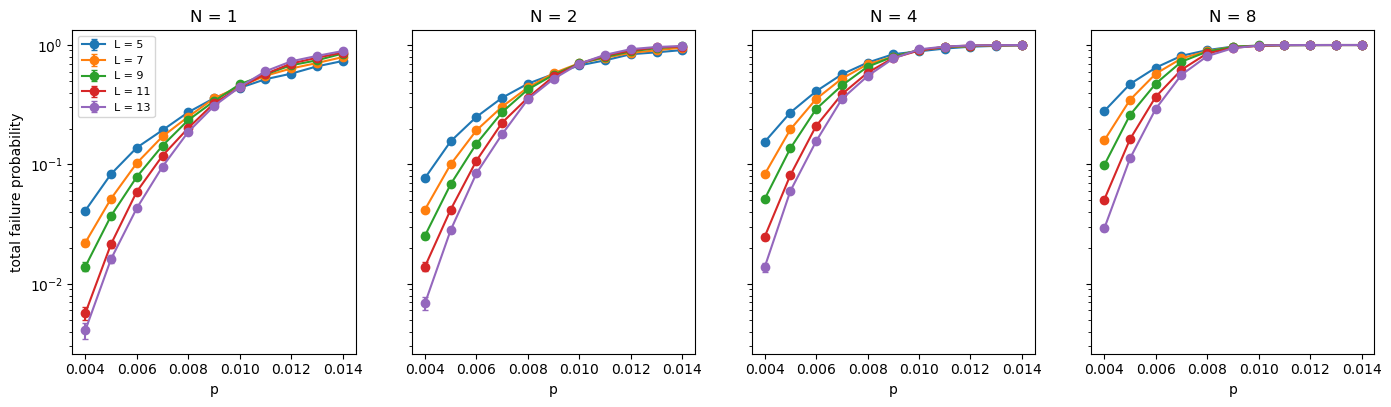

In [2]:
fig, axes = plt.subplots(1, len(N_VALUES), figsize=(4.2 * len(N_VALUES), 4.2), sharey=True)
for ax, N in zip(np.atleast_1d(axes), N_VALUES):
    for L in L_VALUES:
        ps, rates, errs = [], [], []
        for p in P_VALUES:
            rec = groups.get((GAP, L, p, N))
            if rec is None:
                continue
            r = rec["failures"] / rec["trials"]
            ps.append(p)
            rates.append(r)
            errs.append(np.sqrt(r * (1 - r) / rec["trials"]))
        ax.errorbar(ps, rates, yerr=errs, fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_xlabel("p")
    ax.set_title(f"N = {N}")
np.atleast_1d(axes)[0].set_ylabel("total failure probability")
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.show()

## 2. Logical-error propagation

With A as target, A's Z logical errors are copied into every later partner, so the partners' final Z failures grow with their index. The own-fault counts (final readout XOR the snapshot frames inherited at the CNOTs) remove the propagated part.

In [3]:
L_show, p_show, N_show = max(L_VALUES), 0.008, max(N_VALUES)
rec = groups[(GAP, L_show, p_show, N_show)]
rows = ["| partner j | final Z failures | own Z failures | final X failures | own X failures |", "| --- | --- | --- | --- | --- |"]
for j in range(N_show):
    rows.append(
        f"| {j + 1} | {int(rec['partner_z_failures_by_index'][j])} | {int(rec['partner_z_own_failures_by_index'][j])} | "
        f"{int(rec['partner_x_failures_by_index'][j])} | {int(rec['partner_x_own_failures_by_index'][j])} |"
    )
display(Markdown(
    f"`L = {L_show}`, `p = {p_show}`, `N = {N_show}`, {int(rec['trials'])} trials. Hub: X final {int(rec['hub_x_failures'])}, "
    f"X own {int(rec['hub_x_own_failures'])}, Z {int(rec['hub_z_failures'])}. Trials failing: {int(rec['failures'])}; "
    f"trials with an own fault: {int(rec['own_failure_trials'])}.\n\n" + "\n".join(rows)
))

`L = 13`, `p = 0.008`, `N = 8`, 1857 trials. Hub: X final 740, X own 740, Z 460. Trials failing: 1500; trials with an own fault: 1500.

| partner j | final Z failures | own Z failures | final X failures | own X failures |
| --- | --- | --- | --- | --- |
| 1 | 120 | 120 | 75 | 75 |
| 2 | 191 | 120 | 78 | 78 |
| 3 | 258 | 126 | 82 | 82 |
| 4 | 322 | 130 | 72 | 72 |
| 5 | 363 | 131 | 68 | 68 |
| 6 | 416 | 138 | 74 | 74 |
| 7 | 473 | 139 | 70 | 70 |
| 8 | 535 | 147 | 73 | 73 |

A single point is noisy. Pooled over all `p` at the largest `N`, the own-fault counts should be flat in the partner index while the final Z counts grow. Slopes are per unit index, relative to the mean count (Poisson errors).

In [4]:
N_prof = max(N_VALUES)
j_idx = np.arange(1, N_prof + 1)

def rel_slope(counts):
    counts = np.asarray(counts, dtype=float)
    mean = counts.mean()
    slope = np.polyfit(j_idx, counts / mean, 1)[0]
    err = np.sqrt(np.sum((j_idx - j_idx.mean()) ** 2 * counts)) / mean / np.sum((j_idx - j_idx.mean()) ** 2)
    return slope, err

profile_keys = {"final Z": "partner_z_failures_by_index", "own Z": "partner_z_own_failures_by_index",
                "own X": "partner_x_own_failures_by_index"}
rows = ["| L | " + " | ".join(f"{k} slope" for k in profile_keys) + " |", "| --- |" + " --- |" * len(profile_keys)]
for L in L_VALUES:
    sums = {k: np.zeros(N_prof) for k in profile_keys}
    for p in P_VALUES:
        rec = groups.get((GAP, L, p, N_prof))
        if rec is not None:
            for k, key in profile_keys.items():
                sums[k] += np.asarray(rec[key], dtype=float)
    rows.append(f"| {L} | " + " | ".join("{:+.3f} ± {:.3f}".format(*rel_slope(v)) for v in sums.values()) + " |")
total_trials = sum(g["trials"] for g in groups.values())
display(Markdown(
    "\n".join(rows) + "\n\n"
    f"Over the whole scan: {int(sum(g['failures'] for g in groups.values()))} failing trials, "
    f"{int(sum(g['own_failure_trials'] for g in groups.values()))} with an own fault; "
    f"readout cleanup failures {int(sum(g['cleanup_failures'] for g in groups.values()))} and snapshot cleanup failures "
    f"{int(sum(g['snapshot_cleanup_failures'] for g in groups.values()))} in {int(total_trials)} trials."
))

| L | final Z slope | own Z slope | own X slope |
| --- | --- | --- | --- |
| 5 | +0.129 ± 0.002 | +0.002 ± 0.003 | +0.000 ± 0.003 |
| 7 | +0.122 ± 0.002 | +0.002 ± 0.003 | -0.001 ± 0.003 |
| 9 | +0.113 ± 0.002 | +0.004 ± 0.003 | +0.004 ± 0.003 |
| 11 | +0.109 ± 0.002 | +0.002 ± 0.003 | +0.002 ± 0.003 |
| 13 | +0.103 ± 0.002 | +0.001 ± 0.003 | +0.002 ± 0.003 |

Over the whole scan: 294060 failing trials, 293731 with an own fault; readout cleanup failures 1087 and snapshot cleanup failures 252 in 920914 trials.

## 3. Per-gate rate from the decay over `N`

`ln(1 - P_total)` should fall linearly in `N`; the slope gives `eps_CNOT`. Lines are the fits over all `N`.

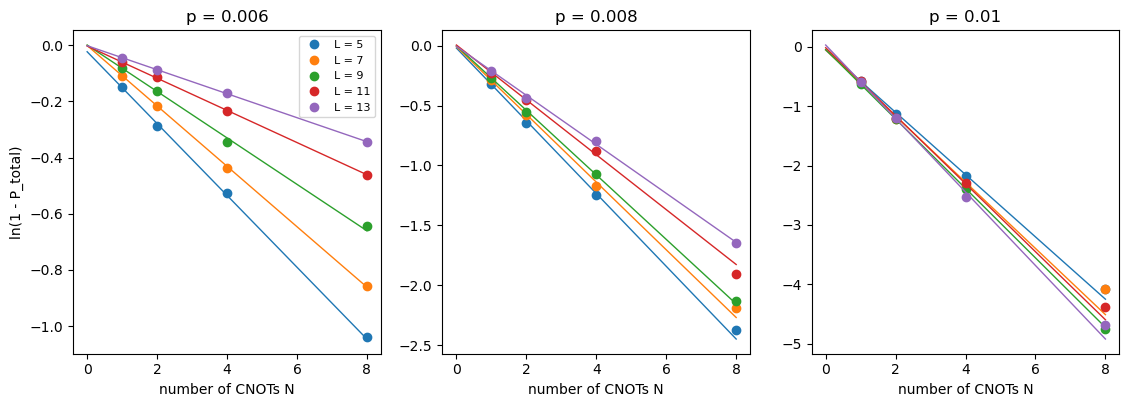

| L | p | eps_CNOT (all N) | eps_CNOT (N >= 2) | intercept B | chi2/dof |
| --- | --- | --- | --- | --- | --- |
| 5 | 0.004 | 0.04041 ± 0.00099 | 0.04102 ± 0.0013 | 1.000 | 1.2/2 |
| 5 | 0.005 | 0.07535 ± 0.0018 | 0.07403 ± 0.0024 | 0.990 | 1.3/2 |
| 5 | 0.006 | 0.1201 ± 0.0027 | 0.1166 ± 0.0038 | 0.977 | 2.1/2 |
| 5 | 0.007 | 0.1902 ± 0.0041 | 0.1823 ± 0.0059 | 0.992 | 3.8/2 |
| 5 | 0.008 | 0.2617 ± 0.0057 | 0.2532 ± 0.0084 | 0.980 | 2.3/2 |
| 5 | 0.009 | 0.3562 ± 0.0081 | 0.3697 ± 0.012 | 1.002 | 3.4/2 |
| 5 | 0.010 | 0.408 ± 0.0097 | 0.3967 ± 0.015 | 0.946 | 1.4/2 |
| 5 | 0.011 | 0.4842 ± 0.013 | 0.4991 ± 0.021 | 0.940 | 1.0/2 |
| 5 | 0.012 | 0.5847 ± 0.014 | 0.5445 ± 0.027 | 1.011 | 4.0/2 |
| 5 | 0.013 | 0.6233 ± 0.019 | 0.6468 ± 0.037 | 0.900 | 0.5/1 |
| 5 | 0.014 | 0.6768 ± 0.022 | 0.7462 ± 0.043 | 0.829 | 2.4/1 |
| 7 | 0.004 | 0.02128 ± 0.0006 | 0.02151 ± 0.00079 | 0.999 | 0.2/2 |
| 7 | 0.005 | 0.05266 ± 0.0012 | 0.05282 ± 0.0017 | 1.001 | 0.7/2 |
| 7 | 0.006 | 0.102 ± 0.0022 | 0.1022 ± 0.0031 | 0.999 | 0.3/2 |
| 7 | 0.007 | 0.1673 ± 0.0036 | 0.1701 ± 0.0052 | 0.996 | 0.6/2 |
| 7 | 0.008 | 0.246 ± 0.0053 | 0.2402 ± 0.0077 | 0.991 | 2.8/2 |
| 7 | 0.009 | 0.3338 ± 0.0078 | 0.3282 ± 0.012 | 0.963 | 2.9/2 |
| 7 | 0.010 | 0.4273 ± 0.01 | 0.3988 ± 0.016 | 0.950 | 8.8/2 |
| 7 | 0.011 | 0.5304 ± 0.014 | 0.5483 ± 0.023 | 0.957 | 1.7/2 |
| 7 | 0.012 | 0.6085 ± 0.017 | 0.5999 ± 0.032 | 0.927 | 0.1/2 |
| 7 | 0.013 | 0.6821 ± 0.02 | 0.7139 ± 0.043 | 0.925 | 0.6/1 |
| 7 | 0.014 | 0.7675 ± 0.023 | 0.7652 ± 0.06 | 0.895 | 0.0/1 |
| 9 | 0.004 | 0.01279 ± 0.00046 | 0.01302 ± 0.0006 | 0.999 | 0.4/2 |
| 9 | 0.005 | 0.03639 ± 0.00092 | 0.03751 ± 0.0012 | 1.001 | 1.9/2 |
| 9 | 0.006 | 0.07938 ± 0.0018 | 0.07972 ± 0.0024 | 1.001 | 3.9/2 |
| 9 | 0.007 | 0.1469 ± 0.0031 | 0.1455 ± 0.0045 | 1.003 | 2.4/2 |
| 9 | 0.008 | 0.236 ± 0.005 | 0.2302 ± 0.0074 | 0.998 | 1.2/2 |
| 9 | 0.009 | 0.3359 ± 0.0076 | 0.3349 ± 0.012 | 0.996 | 0.9/2 |
| 9 | 0.010 | 0.4428 ± 0.011 | 0.4464 ± 0.018 | 0.955 | 0.1/2 |
| 9 | 0.011 | 0.5432 ± 0.014 | 0.5631 ± 0.025 | 0.952 | 1.4/2 |
| 9 | 0.012 | 0.6254 ± 0.018 | 0.593 ± 0.04 | 0.856 | 1.0/1 |
| 9 | 0.013 | 0.7578 ± 0.02 | 0.7179 ± 0.055 | 1.050 | 0.7/1 |
| 9 | 0.014 | 0.809 ± 0.026 | 0.7814 ± 0.079 | 0.789 | 0.2/1 |
| 11 | 0.004 | 0.006577 ± 0.00031 | 0.006274 ± 0.00043 | 1.000 | 1.9/2 |
| 11 | 0.005 | 0.02174 ± 0.00061 | 0.02209 ± 0.0008 | 1.001 | 1.1/2 |
| 11 | 0.006 | 0.05568 ± 0.0013 | 0.05677 ± 0.0018 | 0.997 | 1.5/2 |
| 11 | 0.007 | 0.1145 ± 0.0025 | 0.1124 ± 0.0035 | 0.994 | 0.8/2 |
| 11 | 0.008 | 0.2046 ± 0.0044 | 0.2085 ± 0.0064 | 1.005 | 3.5/2 |
| 11 | 0.009 | 0.3112 ± 0.0069 | 0.3013 ± 0.01 | 0.976 | 1.6/2 |
| 11 | 0.010 | 0.4359 ± 0.01 | 0.4181 ± 0.017 | 0.984 | 2.2/2 |
| 11 | 0.011 | 0.574 ± 0.015 | 0.5826 ± 0.028 | 1.005 | 0.3/2 |
| 11 | 0.012 | 0.6761 ± 0.02 | 0.6954 ± 0.042 | 0.928 | 0.2/1 |
| 11 | 0.013 | 0.7688 ± 0.022 | 0.7031 ± 0.063 | 0.932 | 1.7/1 |
| 11 | 0.014 | 0.7846 ± 0.029 | 0.7862 ± 0.077 | 0.627 | 0.0/1 |
| 13 | 0.004 | 0.003568 ± 0.00024 | 0.003752 ± 0.00031 | 1.000 | 1.0/2 |
| 13 | 0.005 | 0.01472 ± 0.00049 | 0.0151 ± 0.00064 | 0.999 | 1.8/2 |
| 13 | 0.006 | 0.04183 ± 0.001 | 0.04166 ± 0.0014 | 0.998 | 0.5/2 |
| 13 | 0.007 | 0.1003 ± 0.0022 | 0.1028 ± 0.003 | 1.006 | 5.2/2 |
| 13 | 0.008 | 0.1849 ± 0.0039 | 0.1785 ± 0.0058 | 0.994 | 4.4/2 |
| 13 | 0.009 | 0.3033 ± 0.0067 | 0.2997 ± 0.0099 | 0.991 | 0.8/2 |
| 13 | 0.010 | 0.4614 ± 0.011 | 0.4626 ± 0.017 | 1.030 | 1.7/2 |
| 13 | 0.011 | 0.573 ± 0.016 | 0.579 ± 0.028 | 0.932 | 0.4/2 |
| 13 | 0.012 | 0.6843 ± 0.02 | 0.6247 ± 0.042 | 0.842 | 5.7/2 |
| 13 | 0.013 | 0.7884 ± 0.023 | 0.7305 ± 0.07 | 0.888 | 1.1/1 |
| 13 | 0.014 | 0.8205 ± 0.03 | 0.8157 ± 0.094 | 0.611 | 0.0/1 |

In [5]:
p_panels = [p for p in (0.006, 0.008, 0.010) if any(np.isclose(p, P_VALUES))]
fig, axes = plt.subplots(1, len(p_panels), figsize=(4.5 * len(p_panels), 4.2), sharey=False)
for ax, p in zip(np.atleast_1d(axes), p_panels):
    for L in L_VALUES:
        recs = [(N, groups[(GAP, L, p, N)]) for N in N_VALUES if (GAP, L, p, N) in groups]
        if len(recs) < 2:
            continue
        Ns = np.array([N for N, _ in recs], dtype=float)
        P = np.array([r["failures"] / r["trials"] for _, r in recs])
        line = ax.plot(Ns, np.log1p(-P), "o", label=f"L = {L}")[0]
        fit = hub_gate_rates(groups, GAP, L, p)
        grid = np.linspace(0, Ns.max(), 50)
        ax.plot(grid, np.log(fit.cnot.intercept) + grid * np.log1p(-fit.cnot.eps), "-", color=line.get_color(), lw=1)
    ax.set_xlabel("number of CNOTs N")
    ax.set_title(f"p = {p}")
np.atleast_1d(axes)[0].set_ylabel("ln(1 - P_total)")
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.show()

rates = hub_rate_grids(groups, GAP, L_VALUES, P_VALUES)
rates_N2 = hub_rate_grids(groups, GAP, L_VALUES, P_VALUES, min_N=2)
rows = ["| L | p | eps_CNOT (all N) | eps_CNOT (N >= 2) | intercept B | chi2/dof |", "| --- | --- | --- | --- | --- | --- |"]
for L in L_VALUES:
    for p in P_VALUES:
        try:
            fit = hub_gate_rates(groups, GAP, L, p)
        except ValueError:
            continue
        i, j = L_VALUES.index(L), P_VALUES.index(p)
        rows.append(
            f"| {L} | {p:.3f} | {fit.cnot.eps:.4g} ± {fit.cnot.eps_error:.2g} | "
            f"{rates_N2['cnot'].values[i, j]:.4g} ± {rates_N2['cnot'].errors[i, j]:.2g} | {fit.cnot.intercept:.3f} | "
            f"{fit.cnot.chi2:.1f}/{fit.cnot.dof} |"
        )
display(Markdown("\n".join(rows)))

## 4. Per-gate rates and own-fault components

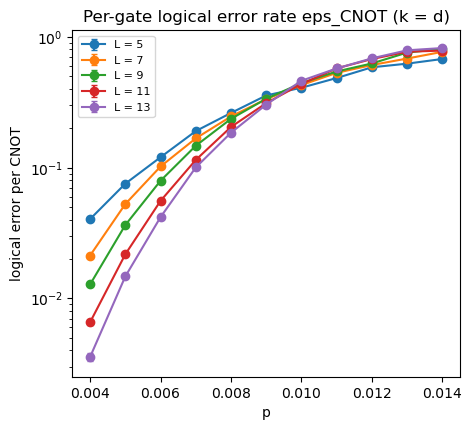

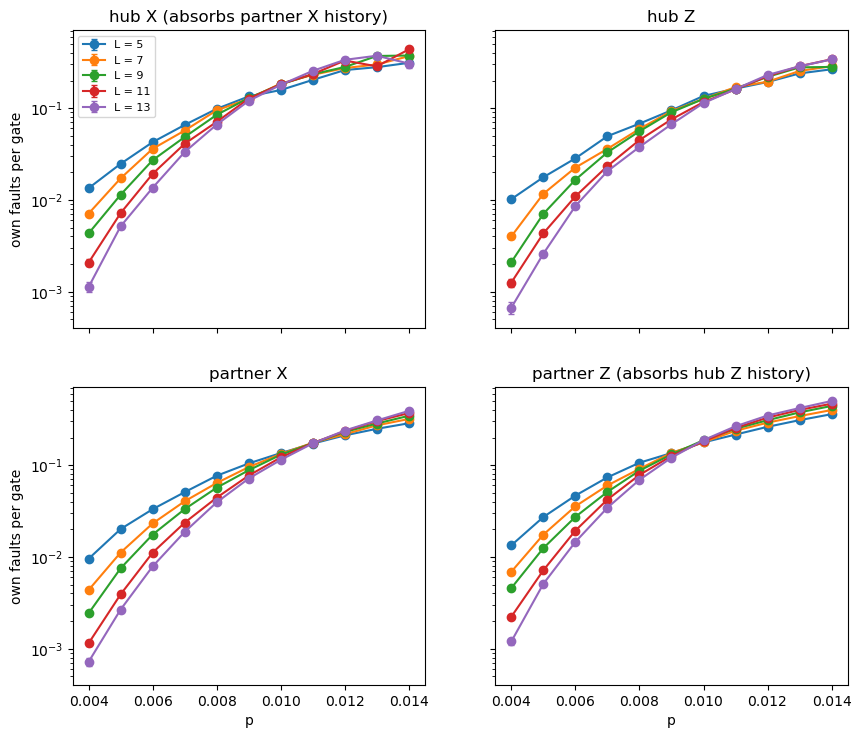

Sum of own-fault components divided by `eps_CNOT` (should be near 1 at low rates):

| L | 0.004 | 0.005 | 0.006 | 0.007 | 0.008 | 0.009 | 0.010 | 0.011 | 0.012 | 0.013 | 0.014 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 1.15 | 1.19 | 1.26 | 1.26 | 1.33 | 1.32 | 1.48 | 1.56 | 1.58 | 1.73 | 1.81 |
| 7 | 1.05 | 1.09 | 1.15 | 1.16 | 1.26 | 1.35 | 1.45 | 1.53 | 1.60 | 1.71 | 1.79 |
| 9 | 1.05 | 1.06 | 1.12 | 1.13 | 1.20 | 1.30 | 1.41 | 1.51 | 1.66 | 1.73 | 1.78 |
| 11 | 1.02 | 1.04 | 1.09 | 1.14 | 1.16 | 1.30 | 1.38 | 1.43 | 1.65 | 1.66 | 2.06 |
| 13 | 1.04 | 1.05 | 1.07 | 1.07 | 1.15 | 1.25 | 1.29 | 1.49 | 1.68 | 1.75 | 1.87 |

In [6]:
def plot_grid(estimate, title, ylabel):
    fig, ax = plt.subplots(figsize=(5, 4.5))
    for i, L in enumerate(L_VALUES):
        ax.errorbar(P_VALUES, estimate.values[i], yerr=estimate.errors[i], fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_xlabel("p")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.show()

plot_grid(rates["cnot"], "Per-gate logical error rate eps_CNOT (k = d)", "logical error per CNOT")

fig, axes = plt.subplots(2, 2, figsize=(10, 8.5), sharex=True, sharey=True)
labels = {"hub_x": "hub X (absorbs partner X history)", "hub_z": "hub Z",
          "partner_x": "partner X", "partner_z": "partner Z (absorbs hub Z history)"}
for ax, (name, label) in zip(axes.flat, labels.items()):
    est = rates[name]
    for i, L in enumerate(L_VALUES):
        ax.errorbar(P_VALUES, est.values[i], yerr=est.errors[i], fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_title(label)
for ax in axes[1]:
    ax.set_xlabel("p")
axes[0, 0].set_ylabel("own faults per gate")
axes[1, 0].set_ylabel("own faults per gate")
axes[0, 0].legend(fontsize=8)
plt.show()

ratio = rates["own_sum"].values / rates["cnot"].values
rows = ["| L | " + " | ".join(f"{p:.3f}" for p in P_VALUES) + " |", "| --- |" + " --- |" * len(P_VALUES)]
for i, L in enumerate(L_VALUES):
    rows.append(f"| {L} | " + " | ".join("" if not np.isfinite(v) else f"{v:.2f}" for v in ratio[i]) + " |")
display(Markdown("Sum of own-fault components divided by `eps_CNOT` (should be near 1 at low rates):\n\n" + "\n".join(rows)))

## 5. Suppression factor `Lambda_CNOT`

In [7]:
def lambda_table(estimate, label):
    rows = [f"| p | Lambda ({label}) | pairwise eps_L / eps_(L+2) |", "| --- | --- | --- |"]
    for j, p in enumerate(P_VALUES):
        try:
            lf = fit_lambda(L_VALUES, estimate.values[:, j], estimate.errors[:, j])
        except ValueError:
            continue
        pairs = ", ".join(
            f"{a}/{b}: {r:.2f}±{e:.2f}"
            for a, b, r, e in lambda_ratios(L_VALUES, estimate.values[:, j], estimate.errors[:, j])
        )
        rows.append(f"| {p:.3f} | {lf.Lambda:.3f} ± {lf.Lambda_error:.3f} | {pairs} |")
    return "\n".join(rows)

display(Markdown(lambda_table(rates["cnot"], "eps_CNOT")))
for name in ("hub_x", "hub_z", "partner_x", "partner_z"):
    display(Markdown(f"**{labels[name]}**\n\n" + lambda_table(rates[name], name)))

| p | Lambda (eps_CNOT) | pairwise eps_L / eps_(L+2) |
| --- | --- | --- |
| 0.004 | 1.819 ± 0.023 | 5/7: 1.90±0.07, 7/9: 1.66±0.08, 9/11: 1.95±0.12, 11/13: 1.84±0.15 |
| 0.005 | 1.509 ± 0.013 | 5/7: 1.43±0.05, 7/9: 1.45±0.05, 9/11: 1.67±0.06, 11/13: 1.48±0.06 |
| 0.006 | 1.310 ± 0.010 | 5/7: 1.18±0.04, 7/9: 1.28±0.04, 9/11: 1.43±0.05, 11/13: 1.33±0.05 |
| 0.007 | 1.180 ± 0.008 | 5/7: 1.14±0.03, 7/9: 1.14±0.03, 9/11: 1.28±0.04, 11/13: 1.14±0.04 |
| 0.008 | 1.092 ± 0.007 | 5/7: 1.06±0.03, 7/9: 1.04±0.03, 9/11: 1.15±0.03, 11/13: 1.11±0.03 |
| 0.009 | 1.040 ± 0.007 | 5/7: 1.07±0.03, 7/9: 0.99±0.03, 9/11: 1.08±0.03, 11/13: 1.03±0.03 |
| 0.010 | 0.974 ± 0.007 | 5/7: 0.95±0.03, 7/9: 0.97±0.03, 9/11: 1.02±0.03, 11/13: 0.94±0.03 |
| 0.011 | 0.959 ± 0.008 | 5/7: 0.91±0.03, 7/9: 0.98±0.04, 9/11: 0.95±0.04, 11/13: 1.00±0.04 |
| 0.012 | 0.959 ± 0.008 | 5/7: 0.96±0.04, 7/9: 0.97±0.04, 9/11: 0.93±0.04, 11/13: 0.99±0.04 |
| 0.013 | 0.943 ± 0.009 | 5/7: 0.91±0.04, 7/9: 0.90±0.04, 9/11: 0.99±0.04, 11/13: 0.98±0.04 |
| 0.014 | 0.959 ± 0.011 | 5/7: 0.88±0.04, 7/9: 0.95±0.04, 9/11: 1.03±0.05, 11/13: 0.96±0.05 |

**hub X (absorbs partner X history)**

| p | Lambda (hub_x) | pairwise eps_L / eps_(L+2) |
| --- | --- | --- |
| 0.004 | 1.835 ± 0.041 | 5/7: 1.89±0.12, 7/9: 1.64±0.13, 9/11: 2.08±0.22, 11/13: 1.84±0.27 |
| 0.005 | 1.494 ± 0.022 | 5/7: 1.44±0.08, 7/9: 1.51±0.09, 9/11: 1.59±0.10, 11/13: 1.39±0.10 |
| 0.006 | 1.335 ± 0.017 | 5/7: 1.18±0.06, 7/9: 1.33±0.07, 9/11: 1.41±0.08, 11/13: 1.42±0.08 |
| 0.007 | 1.184 ± 0.014 | 5/7: 1.15±0.06, 7/9: 1.18±0.06, 9/11: 1.18±0.06, 11/13: 1.23±0.06 |
| 0.008 | 1.114 ± 0.012 | 5/7: 1.04±0.05, 7/9: 1.12±0.05, 9/11: 1.19±0.06, 11/13: 1.07±0.05 |
| 0.009 | 1.022 ± 0.012 | 5/7: 1.06±0.06, 7/9: 0.98±0.05, 9/11: 1.02±0.05, 11/13: 1.06±0.05 |
| 0.010 | 0.978 ± 0.012 | 5/7: 0.85±0.05, 7/9: 1.02±0.06, 9/11: 1.00±0.05, 11/13: 1.02±0.06 |
| 0.011 | 0.954 ± 0.013 | 5/7: 0.88±0.05, 7/9: 0.98±0.06, 9/11: 1.00±0.06, 11/13: 0.92±0.06 |
| 0.012 | 0.932 ± 0.015 | 5/7: 0.95±0.06, 7/9: 0.97±0.06, 9/11: 0.85±0.06, 11/13: 0.98±0.08 |
| 0.013 | 0.943 ± 0.017 | 5/7: 0.93±0.07, 7/9: 0.81±0.06, 9/11: 1.30±0.11, 11/13: 0.77±0.07 |
| 0.014 | 0.961 ± 0.023 | 5/7: 0.85±0.08, 7/9: 0.98±0.10, 9/11: 0.86±0.09, 11/13: 1.43±0.17 |

**hub Z**

| p | Lambda (hub_z) | pairwise eps_L / eps_(L+2) |
| --- | --- | --- |
| 0.004 | 2.033 ± 0.055 | 5/7: 2.55±0.21, 7/9: 1.91±0.21, 9/11: 1.67±0.23, 11/13: 1.88±0.35 |
| 0.005 | 1.614 ± 0.031 | 5/7: 1.51±0.10, 7/9: 1.65±0.12, 9/11: 1.63±0.14, 11/13: 1.67±0.17 |
| 0.006 | 1.364 ± 0.021 | 5/7: 1.26±0.08, 7/9: 1.36±0.09, 9/11: 1.52±0.11, 11/13: 1.27±0.09 |
| 0.007 | 1.246 ± 0.017 | 5/7: 1.37±0.08, 7/9: 1.09±0.07, 9/11: 1.41±0.09, 11/13: 1.14±0.08 |
| 0.008 | 1.155 ± 0.015 | 5/7: 1.14±0.06, 7/9: 1.06±0.06, 9/11: 1.25±0.07, 11/13: 1.19±0.07 |
| 0.009 | 1.094 ± 0.014 | 5/7: 1.02±0.06, 7/9: 1.03±0.05, 9/11: 1.20±0.06, 11/13: 1.13±0.06 |
| 0.010 | 1.045 ± 0.013 | 5/7: 1.08±0.06, 7/9: 1.00±0.05, 9/11: 1.08±0.06, 11/13: 1.02±0.06 |
| 0.011 | 1.008 ± 0.013 | 5/7: 0.96±0.05, 7/9: 1.04±0.06, 9/11: 1.02±0.06, 11/13: 0.99±0.06 |
| 0.012 | 0.952 ± 0.013 | 5/7: 0.99±0.06, 7/9: 0.88±0.06, 9/11: 0.98±0.06, 11/13: 0.97±0.06 |
| 0.013 | 0.952 ± 0.014 | 5/7: 0.94±0.06, 7/9: 0.91±0.06, 9/11: 0.97±0.06, 11/13: 1.00±0.07 |
| 0.014 | 0.936 ± 0.016 | 5/7: 0.92±0.07, 7/9: 1.02±0.08, 9/11: 0.82±0.07, 11/13: 1.00±0.08 |

**partner X**

| p | Lambda (partner_x) | pairwise eps_L / eps_(L+2) |
| --- | --- | --- |
| 0.004 | 1.966 ± 0.035 | 5/7: 2.19±0.11, 7/9: 1.79±0.12, 9/11: 2.12±0.20, 11/13: 1.59±0.20 |
| 0.005 | 1.671 ± 0.019 | 5/7: 1.80±0.07, 7/9: 1.48±0.07, 9/11: 1.92±0.10, 11/13: 1.46±0.10 |
| 0.006 | 1.429 ± 0.013 | 5/7: 1.43±0.05, 7/9: 1.32±0.05, 9/11: 1.57±0.07, 11/13: 1.41±0.07 |
| 0.007 | 1.285 ± 0.010 | 5/7: 1.26±0.04, 7/9: 1.22±0.04, 9/11: 1.41±0.05, 11/13: 1.26±0.05 |
| 0.008 | 1.185 ± 0.008 | 5/7: 1.20±0.03, 7/9: 1.13±0.03, 9/11: 1.28±0.04, 11/13: 1.12±0.04 |
| 0.009 | 1.102 ± 0.007 | 5/7: 1.10±0.03, 7/9: 1.08±0.03, 9/11: 1.14±0.03, 11/13: 1.08±0.03 |
| 0.010 | 1.043 ± 0.005 | 5/7: 1.02±0.02, 7/9: 1.02±0.02, 9/11: 1.07±0.02, 11/13: 1.06±0.03 |
| 0.011 | 0.999 ± 0.004 | 5/7: 0.98±0.02, 7/9: 1.01±0.02, 9/11: 1.00±0.02, 11/13: 1.01±0.02 |
| 0.012 | 0.969 ± 0.004 | 5/7: 0.97±0.02, 7/9: 0.94±0.02, 9/11: 0.98±0.02, 11/13: 0.98±0.02 |
| 0.013 | 0.950 ± 0.003 | 5/7: 0.92±0.01, 7/9: 0.96±0.01, 9/11: 0.94±0.01, 11/13: 0.98±0.01 |
| 0.014 | 0.927 ± 0.003 | 5/7: 0.90±0.01, 7/9: 0.92±0.01, 9/11: 0.93±0.01, 11/13: 0.95±0.01 |

**partner Z (absorbs hub Z history)**

| p | Lambda (partner_z) | pairwise eps_L / eps_(L+2) |
| --- | --- | --- |
| 0.004 | 1.792 ± 0.025 | 5/7: 1.94±0.08, 7/9: 1.51±0.07, 9/11: 2.05±0.14, 11/13: 1.86±0.17 |
| 0.005 | 1.527 ± 0.014 | 5/7: 1.55±0.05, 7/9: 1.40±0.05, 9/11: 1.74±0.07, 11/13: 1.41±0.07 |
| 0.006 | 1.339 ± 0.009 | 5/7: 1.31±0.04, 7/9: 1.30±0.04, 9/11: 1.41±0.05, 11/13: 1.33±0.05 |
| 0.007 | 1.206 ± 0.007 | 5/7: 1.22±0.03, 7/9: 1.17±0.03, 9/11: 1.21±0.03, 11/13: 1.23±0.04 |
| 0.008 | 1.106 ± 0.006 | 5/7: 1.17±0.03, 7/9: 1.05±0.03, 9/11: 1.11±0.03, 11/13: 1.13±0.03 |
| 0.009 | 1.032 ± 0.005 | 5/7: 0.99±0.02, 7/9: 1.04±0.02, 9/11: 1.04±0.02, 11/13: 1.04±0.02 |
| 0.010 | 0.986 ± 0.004 | 5/7: 0.99±0.02, 7/9: 0.95±0.02, 9/11: 1.03±0.02, 11/13: 0.97±0.02 |
| 0.011 | 0.953 ± 0.003 | 5/7: 0.91±0.02, 7/9: 0.95±0.02, 9/11: 0.98±0.02, 11/13: 0.96±0.01 |
| 0.012 | 0.934 ± 0.003 | 5/7: 0.90±0.01, 7/9: 0.94±0.01, 9/11: 0.94±0.01, 11/13: 0.95±0.01 |
| 0.013 | 0.928 ± 0.003 | 5/7: 0.90±0.01, 7/9: 0.91±0.01, 9/11: 0.94±0.01, 11/13: 0.95±0.01 |
| 0.014 | 0.923 ± 0.002 | 5/7: 0.90±0.01, 7/9: 0.90±0.01, 9/11: 0.95±0.01, 11/13: 0.93±0.01 |

## 6. Thresholds

Finite-size crossings of the per-gate rates (fixed aspect ratio for `k = d`), and the point where the fitted `Lambda_CNOT` reaches 1. The main degree-2 fit for each rate uses a window around its crossing: `p` in `[0.008, 0.012]` for the total and the absorbing sectors, `[0.009, 0.014]` for the source sectors. Below 0.008 the rates fall off too fast for a low-order polynomial in the scaling variable.

#### Finite-size scaling fit: eps_CNOT (total)

Degree-2 model: $P_L(p)=A+Bx+Cx^{2}$, with $x=(p-p_c)L^{1/\nu}$. The fit uses $p \in [0.008, 0.012]$ and $L \in [5, 7, 9, 11, 13]$.

| Quantity | Fit result |
|---|---:|
| $p_c$ | 0.0096(1) |
| $p_c$ (%) | 0.96(1) |
| $\nu$ | 1.8(1) |
| $A$ | 0.39(1) |
| $B$ | 30(3) |
| $C$ | 23(95) |
| $\chi^2 / \mathrm{dof}$ | 26.95 / 20 = 1.35 |
| goodness-of-fit $p$-value | 0.137 |

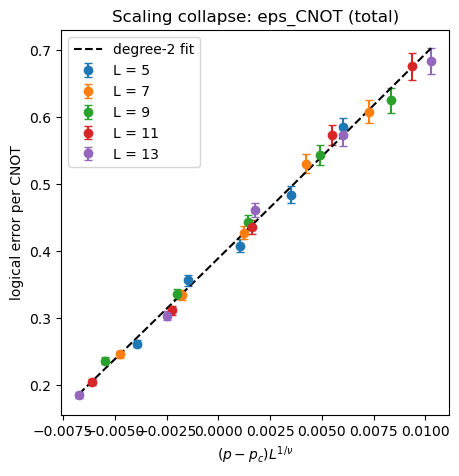

## Per-gate threshold estimates (degree 2, window around each crossing)

| Timing and block | degree | $p_c$ | $p_c$ (%) | $\nu$ | $\chi^2 / \mathrm{dof}$ | fit $p$-value |
|---|---:|---:|---:|---:|---:|---:|
| eps_CNOT (total) | 2 | 0.0096(1) | 0.96(1) | 1.8(1) | 1.35 | 0.137 |
| hub X (absorbs partner X history) | 2 | 0.0095(1) | 0.95(1) | 1.7(2) | 0.90 | 0.59 |
| hub Z | 2 | 0.0108(2) | 1.08(2) | 1.9(2) | 0.96 | 0.516 |
| partner X | 2 | 0.01089(5) | 1.089(5) | 1.85(5) | 1.18 | 0.241 |
| partner Z (absorbs hub Z history) | 2 | 0.00962(5) | 0.962(5) | 1.78(6) | 1.70 | 0.0265 |

In [8]:
scan = rates_as_scan(rates, L_values=L_VALUES, p_values=P_VALUES, label="hub k=d")
MAIN_WINDOWS = {"cnot": (0.008, 0.012), "hub_x": (0.008, 0.012), "partner_z": (0.008, 0.012),
                "hub_z": (0.009, 0.014), "partner_x": (0.009, 0.014)}
rate_labels = {"cnot": "eps_CNOT (total)", **labels}
threshold_fits = []
for name, label in rate_labels.items():
    try:
        fit = fit_finite_size_scaling(scan, rate_name=name, label=label, fit_p_range=MAIN_WINDOWS[name],
                                      min_L=min(L_VALUES), polynomial_degree=2)
        threshold_fits.append(fit)
        if name == "cnot":
            display_finite_size_scaling_fit(fit, "logical error per CNOT")
    except Exception as err:
        print(f"{label}: fit failed ({err})")
display_fit_summary(threshold_fits, title="Per-gate threshold estimates (degree 2, window around each crossing)")

Robustness: the same fits over several windows, polynomial degrees 2 and 3, and minimum size 5 or 7. A fit is dropped if `p_c` sits on a window edge (the fit bound) or its goodness-of-fit p-value is below 0.05; the range is over the remaining fits.

In [9]:
WINDOWS = [(0.007, 0.012), (0.008, 0.012), (0.008, 0.011), (0.009, 0.011),
           (0.009, 0.013), (0.009, 0.014), (0.010, 0.014)]
robust = {}
rows = ["| rate | accepted fits | p_c range (%) | median p_c (%) | dropped: on edge / bad fit |", "| --- | --- | --- | --- | --- |"]
for name, label in rate_labels.items():
    accepted, edge, bad = [], 0, 0
    for window_try in WINDOWS:
        for degree in (2, 3):
            for min_L in (5, 7):
                try:
                    fit = fit_finite_size_scaling(scan, rate_name=name, label=label, fit_p_range=window_try,
                                                  min_L=min_L, polynomial_degree=degree)
                except Exception:
                    bad += 1
                    continue
                if min(abs(fit.pc - window_try[0]), abs(fit.pc - window_try[1])) < 2e-5:
                    edge += 1
                elif fit.p_value < 0.05:
                    bad += 1
                else:
                    accepted.append(fit.pc)
    robust[name] = np.array(accepted)
    span = (f"{100 * min(accepted):.3f} – {100 * max(accepted):.3f} | {100 * np.median(accepted):.3f}"
            if accepted else "– | –")
    rows.append(f"| {label} | {len(accepted)} | {span} | {edge} / {bad} |")
display(Markdown("\n".join(rows)))

| rate | accepted fits | p_c range (%) | median p_c (%) | dropped: on edge / bad fit |
| --- | --- | --- | --- | --- |
| eps_CNOT (total) | 21 | 0.951 – 0.970 | 0.964 | 4 / 3 |
| hub X (absorbs partner X history) | 18 | 0.940 – 0.988 | 0.951 | 2 / 8 |
| hub Z | 20 | 1.083 – 1.119 | 1.096 | 8 / 0 |
| partner X | 20 | 1.089 – 1.112 | 1.101 | 6 / 2 |
| partner Z (absorbs hub Z history) | 13 | 0.960 – 0.984 | 0.973 | 4 / 11 |

In [10]:
lam = []
for j, p in enumerate(P_VALUES):
    try:
        lf = fit_lambda(L_VALUES, rates["cnot"].values[:, j], rates["cnot"].errors[:, j])
        lam.append((p, lf.Lambda))
    except ValueError:
        pass
lam = np.array(lam)
crossing = None
for (p0, l0), (p1, l1) in zip(lam[:-1], lam[1:]):
    if (l0 - 1) * (l1 - 1) <= 0 and l0 != l1:
        crossing = p0 + (1 - l0) * (p1 - p0) / (l1 - l0)
        break
display(Markdown(f"`Lambda_CNOT = 1` near p = {crossing:.4f}" if crossing else "`Lambda_CNOT` does not cross 1 on this grid"))

`Lambda_CNOT = 1` near p = 0.0096

## 7. Comparison with Stage 1

**Single gadget.** The hub circuit with `N = 1` is the Stage-1 gadget (consecutive `[d, d]`, checked trial for trial in the test suite), so its failure probability should agree with the Stage-1 `gadget_cnot_P2r10` scan, which used independent seeds. The last column compares the per-gate rate from the decay over `N` with that single-gadget probability: a ratio near 1 means a gate in the repeated circuit costs the same as an isolated one.

In [11]:
from analysis_utils import parse_result_file

STAGE1 = PROJECT_DIR / "results/cnot_primitive_xz/stage1"
gadget = {}
for path in (STAGE1 / "gadget_cnot_P2r10").glob("2d_XZ_*.txt"):
    rec = parse_result_file(path)
    gadget[(int(rec["L"]), round(float(rec["p"]), 4))] = rec
rows = ["| L | p | hub N = 1 | Stage-1 gadget | z | eps_CNOT / P_hub(N = 1) |", "| --- | --- | --- | --- | --- | --- |"]
zs = []
for i, L in enumerate(L_VALUES):
    for j, p in enumerate(P_VALUES):
        hub1, s1 = groups.get((GAP, L, p, 1)), gadget.get((L, round(p, 4)))
        if hub1 is None or s1 is None:
            continue
        a, n, b, m = hub1["failures"], hub1["trials"], s1["failures"], s1["trials"]
        pool = (a + b) / (n + m)
        z = (a / n - b / m) / np.sqrt(pool * (1 - pool) * (1 / n + 1 / m))
        zs.append(z)
        rows.append(f"| {L} | {p:.3f} | {a / n:.4f} | {b / m:.4f} | {z:+.2f} | {rates['cnot'].values[i, j] / (a / n):.2f} |")
zs = np.array(zs)
display(Markdown(
    f"{zs.size} points: sum of z² = {np.sum(zs ** 2):.1f} (expected {zs.size} ± {np.sqrt(2 * zs.size):.0f}), "
    f"mean z = {zs.mean():+.2f}.\n\n" + "\n".join(rows)
))

50 points: sum of z² = 40.8 (expected 50 ± 10), mean z = -0.04.

| L | p | hub N = 1 | Stage-1 gadget | z | eps_CNOT / P_hub(N = 1) |
| --- | --- | --- | --- | --- | --- |
| 5 | 0.004 | 0.0412 | 0.0417 | -0.21 | 0.98 |
| 5 | 0.005 | 0.0833 | 0.0803 | +0.86 | 0.90 |
| 5 | 0.006 | 0.1384 | 0.1304 | +1.71 | 0.87 |
| 5 | 0.007 | 0.1938 | 0.2014 | -1.17 | 0.98 |
| 5 | 0.008 | 0.2739 | 0.2645 | +1.13 | 0.96 |
| 5 | 0.009 | 0.3584 | 0.3458 | +1.22 | 0.99 |
| 5 | 0.010 | 0.4377 | 0.4490 | -0.93 | 0.93 |
| 5 | 0.011 | 0.5174 | 0.4998 | +1.35 | 0.94 |
| 5 | 0.012 | 0.5758 | 0.6056 | -2.16 | 1.02 |
| 5 | 0.013 | 0.6625 | 0.6745 | -0.85 | 0.94 |
| 7 | 0.004 | 0.0222 | 0.0206 | +0.86 | 0.96 |
| 7 | 0.005 | 0.0518 | 0.0508 | +0.35 | 1.02 |
| 7 | 0.006 | 0.1028 | 0.0985 | +1.10 | 0.99 |
| 7 | 0.007 | 0.1717 | 0.1653 | +1.14 | 0.97 |
| 7 | 0.008 | 0.2510 | 0.2517 | -0.10 | 0.98 |
| 7 | 0.009 | 0.3573 | 0.3645 | -0.68 | 0.93 |
| 7 | 0.010 | 0.4498 | 0.4600 | -0.83 | 0.95 |
| 7 | 0.011 | 0.5531 | 0.5517 | +0.11 | 0.96 |
| 7 | 0.012 | 0.6361 | 0.6477 | -0.82 | 0.96 |
| 7 | 0.013 | 0.7072 | 0.7264 | -1.38 | 0.96 |
| 9 | 0.004 | 0.0140 | 0.0142 | -0.13 | 0.91 |
| 9 | 0.005 | 0.0372 | 0.0351 | +0.89 | 0.98 |
| 9 | 0.006 | 0.0788 | 0.0782 | +0.17 | 1.01 |
| 9 | 0.007 | 0.1439 | 0.1464 | -0.51 | 1.02 |
| 9 | 0.008 | 0.2353 | 0.2316 | +0.50 | 1.00 |
| 9 | 0.009 | 0.3386 | 0.3382 | +0.04 | 0.99 |
| 9 | 0.010 | 0.4688 | 0.4714 | -0.21 | 0.94 |
| 9 | 0.011 | 0.5673 | 0.5760 | -0.64 | 0.96 |
| 9 | 0.012 | 0.6772 | 0.6983 | -1.51 | 0.92 |
| 9 | 0.013 | 0.7444 | 0.7478 | -0.24 | 1.02 |
| 11 | 0.004 | 0.0057 | 0.0045 | +1.28 | 1.15 |
| 11 | 0.005 | 0.0216 | 0.0227 | -0.56 | 1.01 |
| 11 | 0.006 | 0.0593 | 0.0566 | +0.90 | 0.94 |
| 11 | 0.007 | 0.1185 | 0.1176 | +0.20 | 0.97 |
| 11 | 0.008 | 0.2019 | 0.2109 | -1.34 | 1.01 |
| 11 | 0.009 | 0.3251 | 0.3291 | -0.41 | 0.96 |
| 11 | 0.010 | 0.4413 | 0.4561 | -1.21 | 0.99 |
| 11 | 0.011 | 0.5727 | 0.5785 | -0.42 | 1.00 |
| 11 | 0.012 | 0.7003 | 0.6878 | +0.89 | 0.97 |
| 11 | 0.013 | 0.7825 | 0.7740 | +0.63 | 0.98 |
| 13 | 0.004 | 0.0041 | 0.0035 | +0.72 | 0.87 |
| 13 | 0.005 | 0.0162 | 0.0147 | +0.92 | 0.91 |
| 13 | 0.006 | 0.0431 | 0.0426 | +0.19 | 0.97 |
| 13 | 0.007 | 0.0960 | 0.0989 | -0.76 | 1.05 |
| 13 | 0.008 | 0.1875 | 0.1904 | -0.46 | 0.99 |
| 13 | 0.009 | 0.3086 | 0.3191 | -1.10 | 0.98 |
| 13 | 0.010 | 0.4455 | 0.4530 | -0.62 | 1.04 |
| 13 | 0.011 | 0.6027 | 0.6160 | -0.96 | 0.95 |
| 13 | 0.012 | 0.7303 | 0.7150 | +1.10 | 0.94 |
| 13 | 0.013 | 0.8108 | 0.8143 | -0.27 | 0.97 |

**Idle reference.** From the Stage-1 memory scans (`T = d, 2d, 4d`), the per-round rate `eps_mem` gives a memory error for the same spacetime volume as one gate of this circuit, `(d+1)` hub rounds plus `(2d+1)` partner rounds, i.e. `1 - (1 - eps_mem)^(3d+2)`. The ratio shows what the gate costs beyond idling. The memory scans start at `p = 0.008`, so only the upper part of the grid is covered.

In [12]:
P_MEM = [round(0.008 + 0.002 * i, 3) for i in range(9)]
memory_T = {
    f: load_ft_scan(STAGE1 / f"memory_T{f}d", p_values=P_MEM, L_values=L_VALUES, expected_repeats=1,
                    result_pattern="2d_XZ_*.txt", success_field="Ft", scan_label=f"memory_T{f}d")
    for f in (1, 2, 4)
}
rows = ["| L | p | eps_CNOT | idle reference (3d+2 rounds) | ratio |", "| --- | --- | --- | --- | --- |"]
for i, L in enumerate(L_VALUES):
    for j, p in enumerate(P_VALUES):
        if not any(np.isclose(p, P_MEM)) or not np.isfinite(rates["cnot"].values[i, j]):
            continue
        mj = int(np.argmin(np.abs(np.array(P_MEM) - p)))
        units, fails, trials = [], [], []
        for f, s in memory_T.items():
            t = s.trials[i, mj]
            if t > 0:
                units.append(f * L)
                fails.append(s.rate().values[i, mj] * t)
                trials.append(t)
        try:
            eps_mem = fit_decay_rate(units, fails, trials, p_max=P_MAX_BLOCK).eps
        except ValueError:
            continue
        ref = 1 - (1 - eps_mem) ** (3 * L + 2)
        rows.append(f"| {L} | {p:.3f} | {rates['cnot'].values[i, j]:.4f} | {ref:.4f} | {rates['cnot'].values[i, j] / ref:.2f} |")
display(Markdown("\n".join(rows)))

| L | p | eps_CNOT | idle reference (3d+2 rounds) | ratio |
| --- | --- | --- | --- | --- |
| 5 | 0.008 | 0.2617 | 0.0220 | 11.91 |
| 5 | 0.010 | 0.4080 | 0.0417 | 9.78 |
| 5 | 0.012 | 0.5847 | 0.0774 | 7.56 |
| 5 | 0.014 | 0.6768 | 0.1258 | 5.38 |
| 7 | 0.008 | 0.2460 | 0.0105 | 23.48 |
| 7 | 0.010 | 0.4273 | 0.0262 | 16.34 |
| 7 | 0.012 | 0.6085 | 0.0572 | 10.64 |
| 7 | 0.014 | 0.7675 | 0.1033 | 7.43 |
| 9 | 0.008 | 0.2360 | 0.0066 | 35.59 |
| 9 | 0.010 | 0.4428 | 0.0184 | 24.09 |
| 9 | 0.012 | 0.6254 | 0.0454 | 13.77 |
| 9 | 0.014 | 0.8090 | 0.0903 | 8.96 |
| 11 | 0.008 | 0.2046 | 0.0024 | 84.85 |
| 11 | 0.010 | 0.4359 | 0.0113 | 38.44 |
| 11 | 0.012 | 0.6761 | 0.0267 | 25.35 |
| 11 | 0.014 | 0.7846 | 0.0669 | 11.73 |
| 13 | 0.008 | 0.1849 | 0.0014 | 129.90 |
| 13 | 0.010 | 0.4614 | 0.0060 | 77.05 |
| 13 | 0.012 | 0.6843 | 0.0197 | 34.77 |
| 13 | 0.014 | 0.8205 | 0.0573 | 14.32 |

## 8. Summary

In [13]:
lines = ["| Quantity | Estimate |", "| --- | --- |"]
for fit in threshold_fits:
    lines.append(f"| crossing, {fit.label} (window {fit.fit_p_range}, degree 2) | p_c = {100 * fit.pc:.3f} ± {100 * fit.pc_error:.3f} % "
                 f"(chi2/dof = {fit.chi2:.1f}/{fit.dof}) |")
for name, label in rate_labels.items():
    if robust[name].size:
        lines.append(f"| crossing range over fit choices, {label} | {100 * robust[name].min():.3f} – {100 * robust[name].max():.3f} % "
                     f"({robust[name].size} fits) |")
if crossing:
    lines.append(f"| Lambda_CNOT = 1 | p ≈ {crossing:.4f} |")
for p in (0.004, 0.005, 0.006):
    if any(np.isclose(p, P_VALUES)):
        j = P_VALUES.index(p)
        try:
            lf = fit_lambda(L_VALUES, rates["cnot"].values[:, j], rates["cnot"].errors[:, j])
            lines.append(f"| Lambda_CNOT at p = {p} | {lf.Lambda:.2f} ± {lf.Lambda_error:.2f} |")
        except ValueError:
            pass
display(Markdown("\n".join(lines)))

| Quantity | Estimate |
| --- | --- |
| crossing, eps_CNOT (total) (window (0.008, 0.012), degree 2) | p_c = 0.958 ± 0.011 % (chi2/dof = 27.0/20) |
| crossing, hub X (absorbs partner X history) (window (0.008, 0.012), degree 2) | p_c = 0.950 ± 0.013 % (chi2/dof = 18.0/20) |
| crossing, hub Z (window (0.009, 0.014), degree 2) | p_c = 1.083 ± 0.018 % (chi2/dof = 24.1/25) |
| crossing, partner X (window (0.009, 0.014), degree 2) | p_c = 1.089 ± 0.005 % (chi2/dof = 29.6/25) |
| crossing, partner Z (absorbs hub Z history) (window (0.008, 0.012), degree 2) | p_c = 0.962 ± 0.005 % (chi2/dof = 33.9/20) |
| crossing range over fit choices, eps_CNOT (total) | 0.951 – 0.970 % (21 fits) |
| crossing range over fit choices, hub X (absorbs partner X history) | 0.940 – 0.988 % (18 fits) |
| crossing range over fit choices, hub Z | 1.083 – 1.119 % (20 fits) |
| crossing range over fit choices, partner X | 1.089 – 1.112 % (20 fits) |
| crossing range over fit choices, partner Z (absorbs hub Z history) | 0.960 – 0.984 % (13 fits) |
| Lambda_CNOT = 1 | p ≈ 0.0096 |
| Lambda_CNOT at p = 0.004 | 1.82 ± 0.02 |
| Lambda_CNOT at p = 0.005 | 1.51 ± 0.01 |
| Lambda_CNOT at p = 0.006 | 1.31 ± 0.01 |

## Findings (first local pass, 2026-11-09)

Data: `k = d`, `L` 5–13, `N` 1, 2, 4, 8, `p` 0.4–1.4%, each point run to 1500 failures or 10^4 trials (`jobs/cnot_primitive_xz_hub_local.jl`, 8 threads, 1.2 h in total).

- `ln(1 - P_total)` is linear in `N`, and `B` is 0.98–1.01 for `p <= 0.8%`: A's extra `d` idle rounds are negligible next to a gate. `eps_CNOT` equals the `N = 1` failure probability within errors (ratio 0.87–1.15), and the hub `N = 1` points agree with the independent Stage-1 gadget scan (50 points, sum of z² = 40.8). At this gate density a gate in the repeated circuit costs the same as an isolated one.
- Per-gate threshold from the `eps_CNOT` crossing: 0.958(11)% (degree 2, `p` in [0.008, 0.012]), 0.951–0.970% over fit choices; `Lambda_CNOT = 1` near 0.96%. This matches the Stage-1 gadget threshold (0.97%) and is about half the memory threshold (1.77%).
- `Lambda_CNOT` = 1.82(2) at `p` = 0.4%, 1.51(1) at 0.5%, 1.31(1) at 0.6%, 1.09(1) at 0.8%.
- Own-fault components: the absorbing sectors (hub X, which takes the partners' X decoder state, and partner Z, which takes the hub's Z state) set the threshold at 0.950(13)% and 0.962(5)%. The source sectors (hub Z, partner X) cross at 1.083(18)% and 1.089(5)% (ranges 1.083–1.119% and 1.089–1.112%), about 0.13% higher.
- The snapshots behave as intended: own-fault counts are flat in the partner index (|slope| ≤ 0.004 ± 0.003 per index, against +0.10 to +0.13 for the final Z counts), and 99.9% of failing trials have an own fault.